# 06 · Clasificación del estado de los vehículos: esperando, aparcado o circulando

## Motivación / Objetivos

Cerca de muchos semáforos hay coches aparcados. Si se cuentan como "vehículos esperando", los indicadores de cola y de espera de `05` salen inflados. En una sola imagen, un coche aparcado y uno detenido en rojo son casi indistinguibles. Crear una clase `parked_car` para el detector se descartó: le restaría precisión y no resolvería el problema.

Objetivos:
- Seguir los vehículos entre imágenes consecutivas de las cámaras de referencia (cada 6 s).
- Clasificar cada caja como **esperando**, **aparcado** o **circulando**.
- Validar la clasificación contra los estados marcados a mano en CVAT.

**Objetivos del TFM relacionados:** OE-5 (relación entre el flujo vehicular y los tiempos semafóricos: cola real frente a vehículos aparcados).

**Requisito:** las zonas por cámara y el lote de validación se anotan en `03c_anotacion_zonas_estado_vehiculos`.

## Método

Criterios (implementados en `src/estado_vehiculos.py`, con parámetros en `config.yaml` → `estado_vehiculos`):

- **Zonas por cámara** (`zona_espera`, `zona_aparcamiento`, `paso_peatones`). Cada vehículo se asigna por el **punto inferior central de su caja**, donde la rueda toca el suelo, que es más estable frente a la perspectiva que el centro de la caja. Si un punto cae en varias zonas, gana el aparcamiento.
- **Persistencia temporal.** Las cajas se enlazan entre imágenes consecutivas por solape (IoU ≥ 0,3 para considerar que es el mismo vehículo; ≥ 0,7 para considerar que no se ha movido). Un vehículo **inmóvil más de `tiempo_aparcado_s`** (300 s, unos 3 ciclos semafóricos con sus verdes) está aparcado; uno que espera se detiene en rojo y arranca en verde. Un hueco de más de `max_hueco_s` (15 s) corta el seguimiento.

**Regla por caja:** *aparcado* si está en `zona_aparcamiento` o lleva inmóvil ≥ `tiempo_aparcado_s`; *esperando* si está en `zona_espera`, detenido y no aparcado; *circulando* en el resto.

1. Configuración.
2. Secuencias a 6 s de las cámaras de referencia.
3. Detección de vehículos y semáforos (cajas).
4. Seguimiento y clasificación.
5. Validación con los estados marcados en CVAT.

### 1. Configuración

In [1]:
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
import torch
from ultralytics import YOLO

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from config import PROJECT_ROOT as ROOT, load_config, path
from cvat_lotes import connect, export_car_states, lote_dir
from deteccion import VEHICLE_CLASSES, predict_boxes
from estado_vehiculos import (box_zone, classify_state, continuous_sequences, iou, list_reference_images,
                              load_zones, track_vehicles)
from tiempo import to_local

CFG = load_config()
EV = CFG["estado_vehiculos"]
CAMERAS = [str(c) for c in EV["camaras"]]
ZONES_FILE = ROOT / EV["zonas"]
BOXES_FILE = path("fases") / "vehiculos_cajas.parquet"
DEVICE = 0 if torch.cuda.is_available() else "cpu"

print("Cámaras de referencia:", CAMERAS)
print(f"Aparcado tras {EV['tiempo_aparcado_s']} s inmóvil | hueco máximo {EV['max_hueco_s']} s")
if not load_zones(ZONES_FILE):
    print("Sin zonas: dibujarlas con 03c_anotacion_zonas_estado_vehiculos "
          "(sin ellas ningún vehículo saldrá como 'esperando').")

Cámaras de referencia: ['21547', '21541', '21560', '21563', '21545']
Aparcado tras 300 s inmóvil | hueco máximo 15 s


### 2. Secuencias a 6 s de las cámaras de referencia

Se usan las imágenes de `raw/` (captura cada 6 s en hora punta desde el 17/10/2026) y las de las mediciones de `refresco/` (misma cadencia). Solo se procesan **tramos continuos** en los que las imágenes distan ≤ `max_hueco_s` (`estado_vehiculos.continuous_sequences`); las capturas a 30–60 s no sirven para seguir vehículos.

In [5]:
DIAS = None   # p.ej. 3 para procesar solo los últimos 3 días; None = todo

images_df = list_reference_images(CAMERAS)
if DIAS is not None:
    images_df = images_df[images_df["timestamp"] >= images_df["timestamp"].max() - pd.Timedelta(days=DIAS)]
seq = continuous_sequences(images_df, EV["max_hueco_s"])

print(f"Imágenes de las cámaras de referencia: {len(images_df)} | en secuencias de ≤ {EV['max_hueco_s']} s: {len(seq)}")
display(seq.groupby("camera")["timestamp"].agg(["count", "min", "max"]))

Imágenes de las cámaras de referencia: 13656 | en secuencias de ≤ 15 s: 1246


,count,min,max
camera,,,
21541,255,2026-08-25 16:04:29,2026-10-17 07:35:03
21545,248,2026-08-25 16:04:28,2026-10-15 20:50:19
21547,257,2026-08-25 16:04:28,2026-10-17 07:35:02
21560,233,2026-08-25 16:04:28,2026-10-13 11:17:04
21563,253,2026-08-25 16:04:28,2026-10-17 07:35:02


### 3. Detección de vehículos y semáforos (cajas)

YOLO26 sobre cada imagen de las secuencias. A diferencia de `02c`, que guarda conteos, aquí se guardan **las cajas**, necesarias para el seguimiento, en `fases/vehiculos_cajas.parquet`. Es incremental: solo procesa las imágenes nuevas.

In [6]:
previous = pd.read_parquet(BOXES_FILE) if BOXES_FILE.exists() else pd.DataFrame(columns=["camera", "image"])
previous["camera"] = previous["camera"].astype(str)
done = set(zip(previous["camera"], previous["image"]))
pending = seq[[(c, i) not in done for c, i in zip(seq["camera"], seq["image"])]]
print(f"Imágenes ya procesadas: {len(done)} | pendientes: {len(pending)}")

model = YOLO(CFG["deteccion"]["modelo"])
rows = []
for k, row in enumerate(pending.itertuples(), 1):
    img = cv2.imread(str(ROOT / row.path))
    if img is None:
        continue
    h, w = img.shape[:2]
    boxes = predict_boxes(model, img, conf=CFG["deteccion"]["conf"], imgsz=CFG["deteccion"]["imgsz"], device=DEVICE)
    # Fila "vacía" para registrar también las imágenes sin detecciones
    rows.append({"camera": row.camera, "image": row.image, "timestamp": row.timestamp, "clase": None,
                 "x1": None, "y1": None, "x2": None, "y2": None, "img_w": w, "img_h": h})
    for name, (x1, y1, x2, y2) in boxes:
        rows.append({"camera": row.camera, "image": row.image, "timestamp": row.timestamp, "clase": name,
                     "x1": x1, "y1": y1, "x2": x2, "y2": y2, "img_w": w, "img_h": h})
    if k % 500 == 0:
        print(f"  {k} imágenes procesadas...")

if rows:
    boxes_df = pd.concat([previous, pd.DataFrame(rows)], ignore_index=True)
    BOXES_FILE.parent.mkdir(parents=True, exist_ok=True)
    boxes_df.to_parquet(BOXES_FILE, index=False)
else:
    boxes_df = previous
boxes_df["timestamp"] = pd.to_datetime(boxes_df["timestamp"])
n_imagenes = boxes_df[["camera", "image"]].drop_duplicates().shape[0]   # los nombres se repiten entre cámaras
print(f"Cajas guardadas: {boxes_df['clase'].notna().sum()} en {n_imagenes} imágenes -> {BOXES_FILE}")
display(boxes_df["clase"].value_counts())

Imágenes ya procesadas: 1240 | pendientes: 6


Cajas guardadas: 6433 en 1240 imágenes -> C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\fases\vehiculos_cajas.parquet


clase
car                      3818
pedestrian               1084
bus                       471
truck                     405
traffic_light_unknown     391
traffic_light_yellow      152
motorcycle                 66
traffic_light_red          46
Name: count, dtype: int64

### 4. Seguimiento y clasificación

Para cada cámara se recorren sus imágenes en orden temporal, se enlazan las cajas de vehículos con las del fotograma anterior (`track_vehicles`) y se clasifica cada caja con su zona y el tiempo que lleva inmóvil (`classify_state`).

In [7]:
zones = load_zones(ZONES_FILE)
vehicles = boxes_df[boxes_df["clase"].isin(VEHICLE_CLASSES)].copy()
all_frames = boxes_df[["camera", "image", "timestamp"]].drop_duplicates()

states = []
for cam, frames_cam in all_frames.sort_values("timestamp").groupby("camera"):
    vcam = vehicles[vehicles["camera"] == cam]
    by_image = {img: g for img, g in vcam.groupby("image")}
    sequence, keys = [], []
    for fr in frames_cam.itertuples():
        g = by_image.get(fr.image)
        boxes = [] if g is None else g[["x1", "y1", "x2", "y2"]].to_numpy().tolist()
        sequence.append((fr.timestamp.to_pydatetime(), boxes))
        keys.append(g)
    tracks = track_vehicles(sequence, EV["iou_mismo_vehiculo"], EV["iou_inmovil"], EV["max_hueco_s"])
    for (ts, boxes), g, infos in zip(sequence, keys, tracks):
        if g is None:
            continue
        for (_, box_row), box, info in zip(g.iterrows(), boxes, infos):
            zone = box_zone(box, box_row["img_w"], box_row["img_h"], zones.get(cam))
            still_s = (ts - info["inmovil_desde"]).total_seconds()
            states.append({
                "camera": cam, "image": box_row["image"], "timestamp": ts, "clase": box_row["clase"],
                "x1": box[0], "y1": box[1], "x2": box[2], "y2": box[3],
                "track": f"{cam}-{info['track']}", "zona": zone, "detenido": info["detenido"],
                "inmovil_s": still_s,
                "estado": classify_state(zone, info["detenido"], still_s, EV["tiempo_aparcado_s"]),
            })

states_df = pd.DataFrame(states)
print(f"Cajas de vehículos clasificadas: {len(states_df)} | vehículos seguidos: {states_df['track'].nunique()}")
display(pd.crosstab(states_df["camera"], states_df["estado"], margins=True))

Cajas de vehículos clasificadas: 4760 | vehículos seguidos: 3294


estado,circulando,All
camera,,
21541,855,855
21545,817,817
21547,1902,1902
21560,436,436
21563,750,750
All,4760,4760


estado,circulando
camera,
21541,5.12
21545,4.70
21547,9.46
21560,2.97
21563,3.44


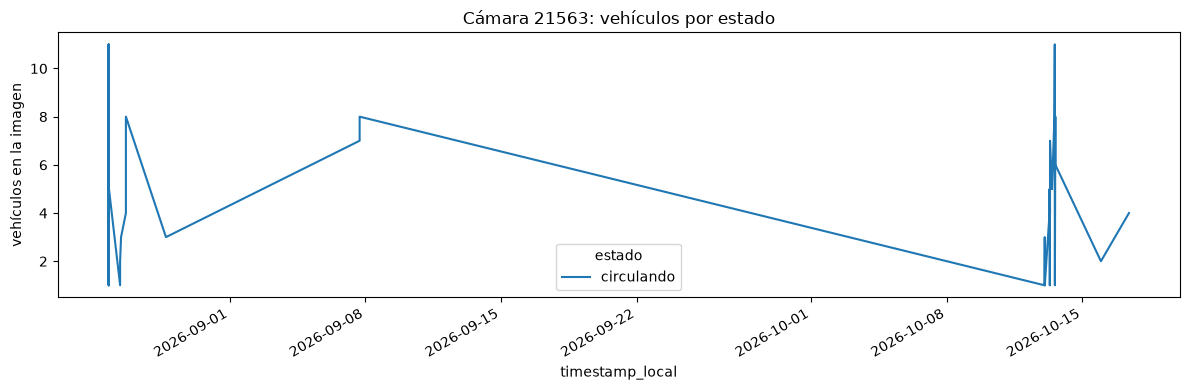

Clasificación guardada en C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\resultados\estado_vehiculos.csv


In [8]:
# Vehículos por imagen según su estado (la "cola" real es la de los que esperan)
per_frame = (states_df.groupby(["camera", "image", "timestamp", "estado"]).size()
             .unstack(fill_value=0).reset_index())
per_frame["timestamp_local"] = per_frame["timestamp"].map(to_local)
display(per_frame.groupby("camera")[[c for c in ["esperando", "aparcado", "circulando"] if c in per_frame]].mean().round(2))

cam = per_frame["camera"].value_counts().idxmax()
serie = per_frame[per_frame["camera"] == cam].set_index("timestamp_local").sort_index()
ax = serie[[c for c in ["esperando", "aparcado", "circulando"] if c in serie]].plot(figsize=(12, 4), title=f"Cámara {cam}: vehículos por estado")
ax.set_ylabel("vehículos en la imagen")
plt.tight_layout()
plt.show()

states_df.to_csv(path("resultados") / "estado_vehiculos.csv", index=False)
print(f"Clasificación guardada en {path('resultados') / 'estado_vehiculos.csv'}")

### 5. Validación con los estados marcados en CVAT

Se comparan las cajas clasificadas con las cajas de `car` a las que se asignó un `estado` en CVAT (el mismo coche, con IoU ≥ 0,5 en la misma imagen). Para tener imágenes comparables hay que crear y revisar el lote de validación de `03c`.

In [10]:
client = connect()

manual = []
for project_task in client.tasks.list():
    lote = project_task.name
    if (lote_dir(lote) / "indice.csv").exists():
        manual.append(export_car_states(client, project_task, lote).assign(lote=lote))
manual = pd.concat(manual, ignore_index=True) if manual else pd.DataFrame()
print(f"Coches con estado marcado en CVAT: {len(manual)}")

if not manual.empty:
    manual["image_orig"] = manual["image"].str.split("_", n=1).str[1]
    auto = states_df.merge(boxes_df[["image", "img_w", "img_h"]].drop_duplicates(), on="image")
    pairs = []
    for m in manual.itertuples():
        cand = auto[(auto["camera"] == m.camera) & (auto["image"] == m.image_orig)]
        if cand.empty:
            continue
        mbox = [m.x1 * cand["img_w"].iloc[0], m.y1 * cand["img_h"].iloc[0], m.x2 * cand["img_w"].iloc[0], m.y2 * cand["img_h"].iloc[0]]
        overlaps = cand.apply(lambda r: iou(mbox, [r.x1, r.y1, r.x2, r.y2]), axis=1)
        if overlaps.max() >= 0.5:
            pairs.append({"manual": m.estado, "automatico": cand.loc[overlaps.idxmax(), "estado"]})
    pairs = pd.DataFrame(pairs)
    if pairs.empty:
        print("Ningún coche marcado está en las secuencias procesadas: crea el lote de validación (celda anterior).")
    else:
        print(f"Coches comparados: {len(pairs)} | acierto: {(pairs['manual'] == pairs['automatico']).mean():.1%}")
        display(pd.crosstab(pairs["manual"], pairs["automatico"], margins=True))

Coches con estado marcado en CVAT: 0


## Salida / Resultados

| Salida | Contenido |
|---|---|
| `data/malaga/fases/vehiculos_cajas.parquet` | Cajas YOLO26 de cada imagen de las secuencias (incremental). |
| `data/malaga/resultados/estado_vehiculos.csv` | Cada caja de vehículo con su seguimiento, zona, tiempo inmóvil y estado. |

**Última ejecución (17/10/2026):**
- 13.656 imágenes de las 5 cámaras de referencia; 1.246 en secuencias de ≤ 15 s.
- 6.433 cajas en 1.240 imágenes (3.818 coches y 1.084 peatones, entre otras).
- 4.760 cajas de vehículos y 3.294 vehículos seguidos. **Todos `circulando`**, porque aún no hay zonas dibujadas y ningún vehículo superó los 300 s inmóvil.
- Validación: 0 coches con `estado` marcado en CVAT.

## Observaciones

- Los resultados no serán significativos hasta dibujar las zonas en `03c`.
- Hay 3.294 seguimientos para 4.760 cajas, apenas 1,4 cajas por vehículo: los seguimientos se cortan pronto. Puede deberse a que las secuencias a 6 s son todavía cortas (la captura a 6 s empezó el 17/10) o a que IoU ≥ 0,3 es exigente para vehículos que se mueven rápido. Conviene revisarlo cuando haya más horas punta capturadas.
- Siguiente paso: llevar el recuento de vehículos `esperando` a los indicadores de cola de `05`.